<h1>Context</h1>
The Matildas - the Australian women's national football team - have played 161 full internationals since the start of 2015: World Cups, Olympic Games, Asian Cups and friendlies, at home and around the world. Each row of this dataset is one match.

Can you tell what drives the size of the crowd?

<h2>Acknowledgements</h2>
Match results compiled from the Wikipedia match record (Australia women's national soccer team results) cross-checked against the open women's international football results dataset by Mart Jürisoo. Attendance figures are from the Wikipedia match reports; for some older away friendlies and minor tournaments no attendance was recorded, so those values are honestly missing. Matches decided on penalties are recorded by the final score after extra time, so they count as draws - the 2023 World Cup quarter-final shoot-out win over France is the famous example. Data compiled August 2026.

In [37]:
# numpy       -> number handling
# pandas      -> loading and working with the data table
# matplotlib  -> plotting
# seaborn     -> nicer statistical plots, used for most charts in this lab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [38]:
# read the Matildas dataset into a DataFrame called df
df = pd.read_csv('data/matildas.csv')

In [39]:
# display the full table - 161 internationals, 8 columns
df

,opponent,year,goals_scored,goals_conceded,attendance,in_australia,match_type,result
0,North Korea,2015,2,1,NaN,No,Friendly,W
1,New Zealand,2015,3,2,NaN,No,Friendly,W
2,Netherlands,2015,1,0,NaN,No,Tournament,W
3,England,2015,0,3,NaN,No,Tournament,L
4,Finland,2015,3,0,NaN,No,Tournament,W
...,...,...,...,...,...,...,...,...
156,Japan,2026,0,1,74397.0,Yes,Tournament,L
157,Malawi,2026,5,0,NaN,No,Tournament,W
158,Kenya,2026,2,0,NaN,No,Tournament,W
159,Mexico,2026,0,1,23167.0,Yes,Friendly,L


So as you can see we have numerical as well as categorical data. Now let's say the problem on hand is a very simple one. We want to understand what drives the attendance at a Matildas match based on the features above. In the least, we want to see which features move together so a model could predict the crowd. But before we even move in that direction, our goal today is to pre-process the data and do some exploratory analysis.

Before exploring, confirm what state the dataset is in. This one has real gaps: attendance was simply never recorded for many older away friendlies and minor tournaments. Counting the gaps - and saying so - is part of good practice.

In [40]:
# count missing values in each column, then count duplicated rows
print("Missing values per column:")
print(df.isnull().sum())
print('\nDuplicates:', df.duplicated().sum())

Missing values per column:
opponent           0
year               0
goals_scored       0
goals_conceded     0
attendance        60
in_australia       0
match_type         0
result             0
dtype: int64

Duplicates: 0


<h1>1. Understand the number of unique values in categorical columns</h1>
The following code will list all the columns and then display the length or the number of unique values in each column. 

In [41]:
# for every column, count how many different values it contains
# (reads as: "column name -> number of unique values", built in one line)
{column:len(df[column].unique()) for column in df.columns}

{'opponent': 46,
 'year': 12,
 'goals_scored': 13,
 'goals_conceded': 7,
 'attendance': 94,
 'in_australia': 2,
 'match_type': 2,
 'result': 3}

<h1>2. Change the columns to binary values</h1>
The following code will change the 'in_australia' and 'match_type' columns to binary values.
in_australia: No = 0, Yes = 1
match_type: Friendly = 0, Tournament = 1

In [42]:
# .map() swaps each text value for a number, using the dictionary given
df['in_australia'] = df['in_australia'].map({'No':0,'Yes':1})
df['match_type'] = df['match_type'].map({'Friendly':0,'Tournament':1})

<h1>3. Change the result column to numerical/ordinal numerical</h1>
The following code will change the 'result' column for the following values:
result: L = 0, D = 1, W = 2

Note: numbering the results imposes an order on them (loss &lt; draw &lt; win) - which here is exactly what we want.

In [43]:
type(df['result'])

pandas.core.series.Series

Reference: [pandas.Series.map](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)

`Series.map(func=None, na_action=None, engine=None, **kwargs)`
Map values of Series according to an input mapping or function.

Used for substituting each value in a Series with another value, that may be derived from a function, a dict or a Series.

When `func` is a dictionary, values in Series that are not in the dictionary (as keys) are converted to `NaN`. However, if the dictionary is a `dict` subclass that defines `__missing__` (i.e. provides a method for default values), then this default is used rather than `NaN`.

The series `map` method should not be confused with the built-in Python [`map()`](https://www.geeksforgeeks.org/python/python-map-function/) function, which applies a function to each item in an iterable and returns a map object (which is an iterator). The series `map` method is specifically designed for pandas Series objects and provides additional functionality, such as handling missing values and working with dictionaries or Series for mapping.

It should not be confused either with the [`pandas.DataFrame.map`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html) method, which is used for element-wise transformations of DataFrame objects.

In [44]:
# same idea for result - three values, numbered from worst to best
df['result'] = df['result'].map({'L':0,'D':1,'W':2})

In [45]:
# opponent has 46 different values - too many to number meaningfully,
# so make it the row label instead: every row is now labelled by who we played
df = df.set_index('opponent')

In [46]:
# look at the table again - every column is now numeric
df

,year,goals_scored,goals_conceded,attendance,in_australia,match_type,result
opponent,,,,,,,
North Korea,2015,2,1,NaN,0,0,2
New Zealand,2015,3,2,NaN,0,0,2
Netherlands,2015,1,0,NaN,0,1,2
England,2015,0,3,NaN,0,1,0
Finland,2015,3,0,NaN,0,1,2
...,...,...,...,...,...,...,...
Japan,2026,0,1,74397.0,1,1,0
Malawi,2026,5,0,NaN,0,1,2
Kenya,2026,2,0,NaN,0,1,2


<h1>4. Exploratory Data Analysis (EDA)</h1>
In this step we will start with some EDA using some Data Visualisation. In this notebook we will have a look at using the library seaborn - another data visualisation library. We will begin with univariate analysis. Meaning we will only understand how individual features are spread.

<h2> Seaborn reference</h2>

[Seaborn histplot reference](https://seaborn.pydata.org/generated/seaborn.histplot.html)

`seaborn.histplot(data=None, *, x=None, y=None, hue=None, weights=None, stat='count', bins='auto', binwidth=None, binrange=None, discrete=None, cumulative=False, common_bins=True, common_norm=True, multiple='layer', element='bars', fill=True, shrink=1, kde=False, kde_kws=None, line_kws=None, thresh=0, pthresh=None, pmax=None, cbar=False, cbar_ax=None, cbar_kws=None, palette=None, hue_order=None, hue_norm=None, color=None, log_scale=None, legend=True, ax=None, **kwargs)`

Plot univariate or bivariate histograms to show distributions of datasets.

A histogram is a classic visualization tool that represents the distribution of one or more variables by counting the number of observations that fall within discrete bins.

This function can normalize the statistic computed within each bin to estimate frequency, density or probability mass, and it can add a smooth curve obtained using a kernel density estimate, similar to kdeplot().

Parameters:

- `kde`: bool

  If True, compute a kernel density estimate to smooth the distribution and show on the plot as (one or more) line(s). Only relevant with univariate data.


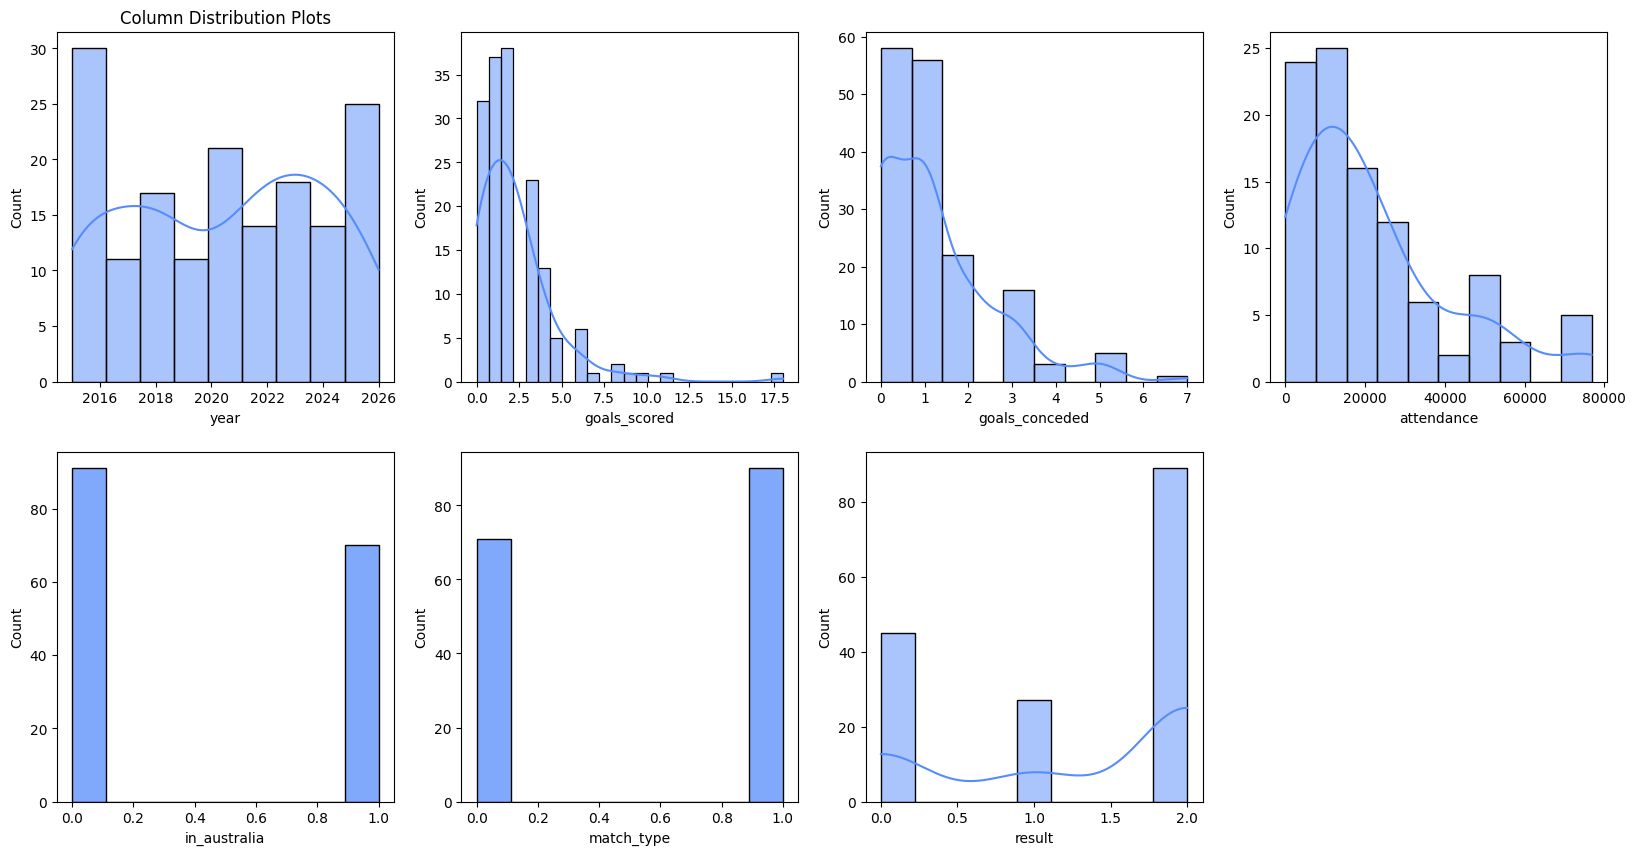

In [47]:
# one histogram per column, laid out in a 2 x 4 grid
plt.figure(figsize=(20,10))

for i in range(len(df.columns)):
    plt.subplot(2,4,i+1)                          # move to the next position in the grid
    if len(df[df.columns[i]].unique()) > 2:
        sns.histplot(df[df.columns[i]], kde = True)   # many values -> add a smooth curve
    else:
        sns.histplot(df[df.columns[i]], kde = False)  # binary column -> just the two bars
    if i == 0:
        plt.title('Column Distribution Plots')


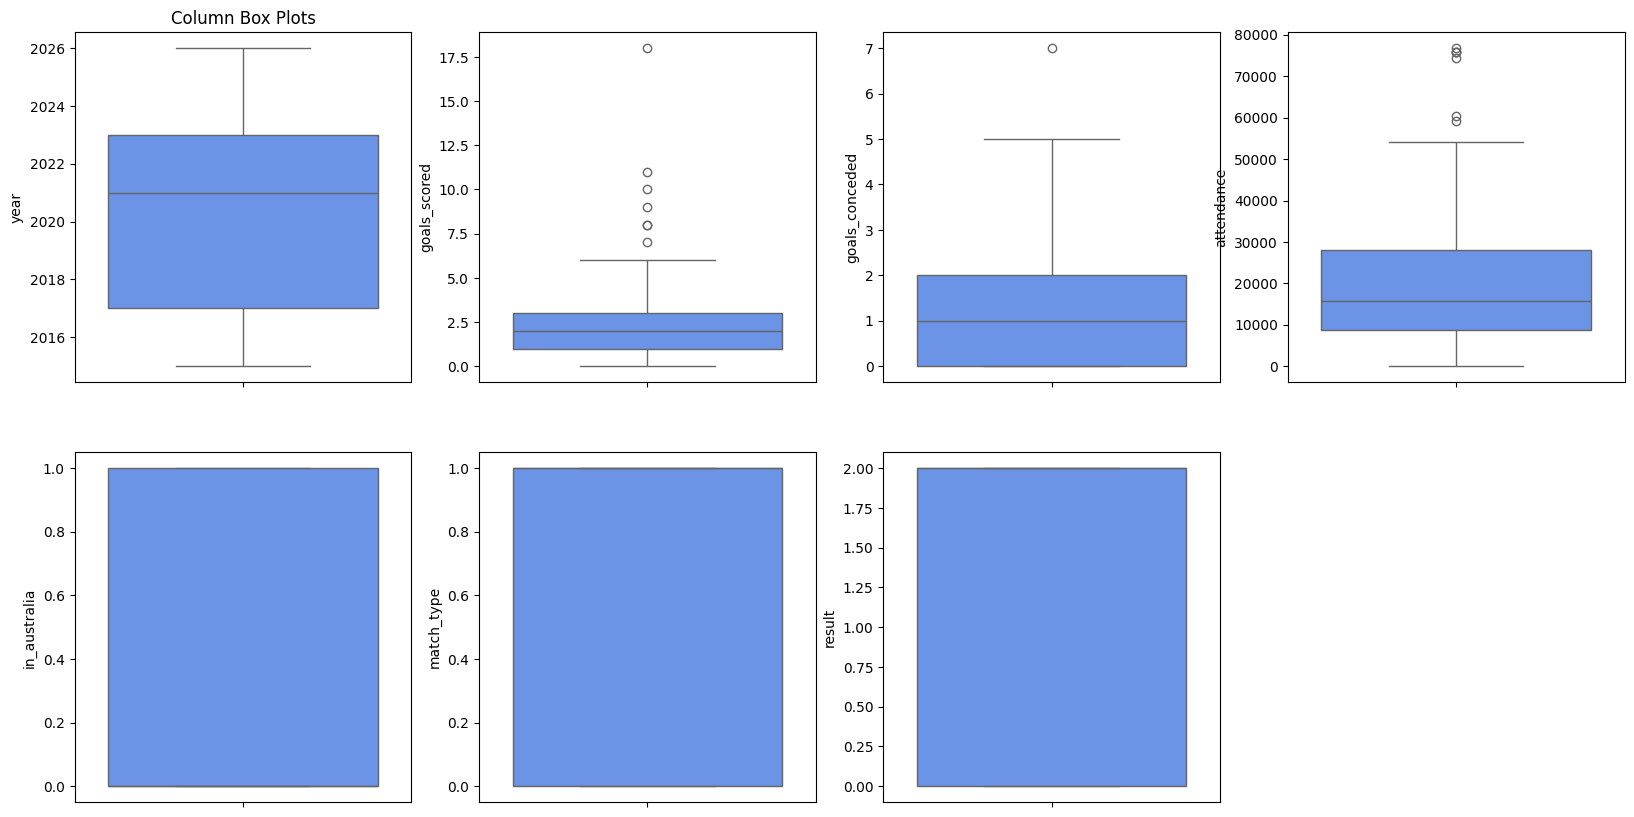

In [48]:
# one box plot per column, same 2 x 4 grid
# the box shows the middle 50% of values; dots beyond the whiskers are outliers
# watch the attendance box - the 75,000+ World Cup nights sit far above the rest
plt.figure(figsize=(20,10))

for i in range(len(df.columns)):
    plt.subplot(2,4,i+1)
    sns.boxplot(df[df.columns[i]])
    if i == 0:
        plt.title('Column Box Plots')

Average attendance by year

Grouping lets us compare a numeric value across categories - and answers a real question: how have Matildas crowds changed over the years?

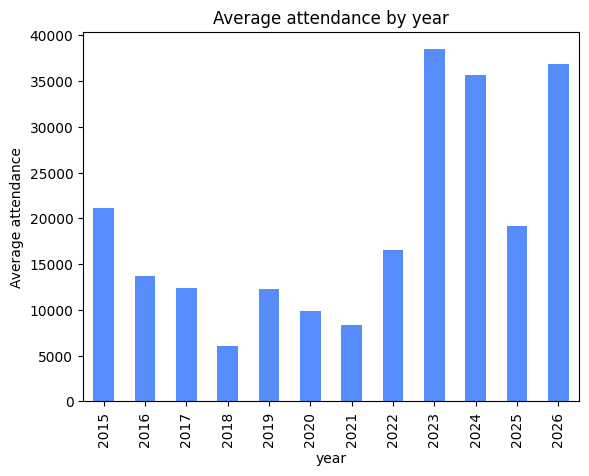

In [49]:
# group the rows by year, average the attendance within each year, and draw it as a bar chart
df.groupby('year')['attendance'].mean().plot(kind='bar')
plt.title('Average attendance by year')
plt.ylabel('Average attendance')
plt.show()

In the original notebook the author forgot to see the years for which we have no attendance data. Let's do that now.

In [50]:
print("Years with missing attendance data:")
df.loc[df['attendance'].isna(), 'year']

Years with missing attendance data:


opponent
North Korea            2015
New Zealand            2015
Netherlands            2015
England                2015
Finland                2015
Czech Republic         2015
Austria                2015
Scotland               2015
Vietnam                2015
Vietnam                2015
China                  2015
England                2015
South Korea            2015
New Zealand            2016
New Zealand            2016
Brazil                 2016
Sweden                 2017
Netherlands            2017
China                  2017
Denmark                2017
Brazil                 2017
Brazil                 2017
China                  2017
China                  2017
Norway                 2018
Portugal               2018
China                  2018
Portugal               2018
Thailand               2018
France                 2018
England                2018
Chile                  2018
Chile                  2018
United States          2019
Netherlands            2019
Chile      

In [51]:
print("Counts of missing attendance data by year:")
df.loc[df['attendance'].isna(), 'year'].value_counts().sort_index()

Counts of missing attendance data by year:


year
2015    13
2016     3
2017     8
2018     9
2019     4
2020     3
2021     6
2022     7
2023     1
2024     4
2026     2
Name: count, dtype: int64

In the next half we will do some multi-variate analysis. Let's say we want to visualise the attendance and goals_scored columns. 

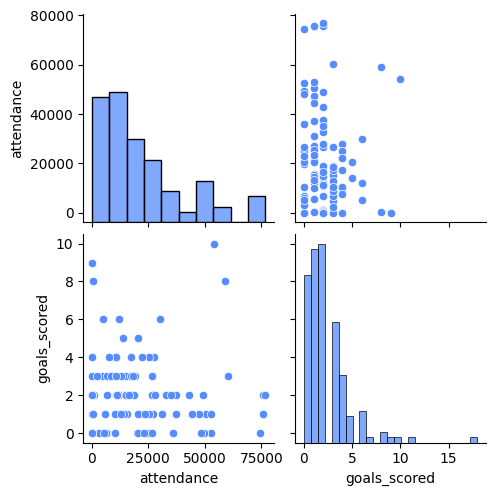

In [52]:
# plot attendance and goals_scored against each other (and each against itself)
# to see whether big crowds and big scorelines go together
# (reset_index(drop=True) sets the opponent labels aside while we plot -
#  seaborn needs unique row labels, and we play some opponents many times)
sns.pairplot(df.loc[:,['attendance','goals_scored']].reset_index(drop=True))

<Axes: >

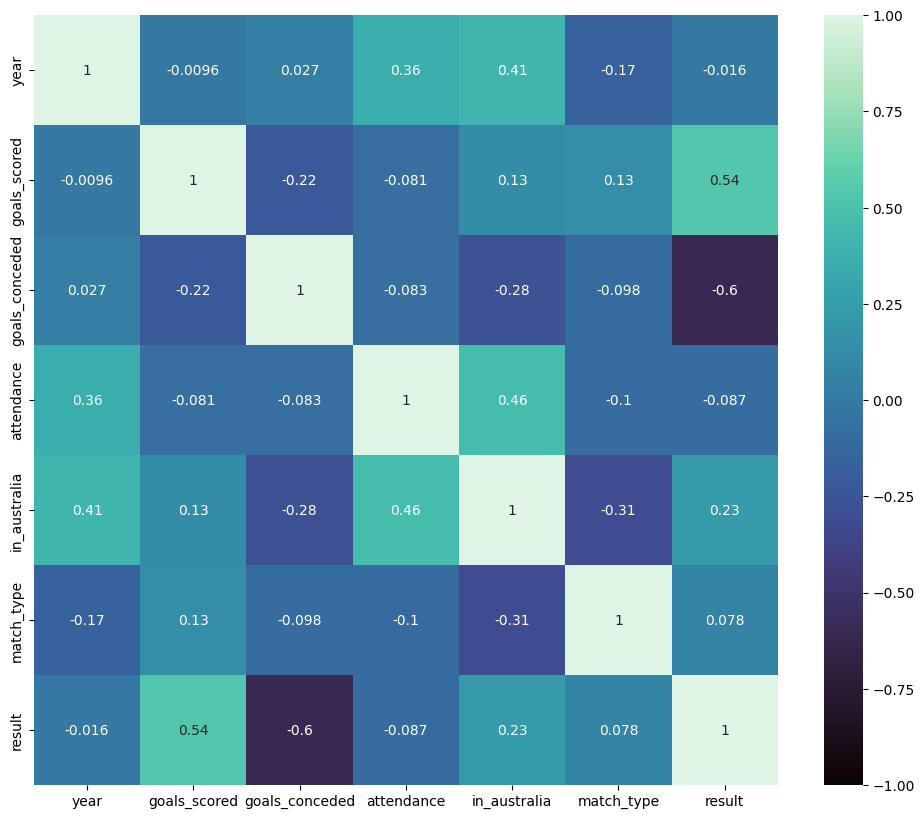

In [53]:
# correlation between every pair of columns, drawn as a heatmap
# (this works because we converted every column to numbers earlier)
# 1 = perfect positive link, 0 = no link, -1 = perfect negative link
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot = True,vmin=-1.0,cmap='mako')

<h1>What did we find?</h1>

If we look at the result row of the heatmap, the strongest correlation is with goals_conceded (≈ -0.60), ahead of goals_scored (≈ 0.54) - in other words, across a decade of matches, not conceding has been slightly more decisive than scoring. Attendance tells its own story: it correlates with in_australia (≈ 0.46) and with year (≈ 0.36) - crowds follow home games, and they have grown across the decade. The year-by-year bar chart shows how sharply: the average crowd since the 2023 World Cup dwarfs the years before it, and the 2021 bar carries the six zero-attendance Tokyo Olympics matches played behind closed doors during COVID.

Attendance and goals_scored, on the other hand, are barely related - big crowds don't make the team score more. And remember the 60 missing attendance values we found at the start: every average we computed silently skipped those matches, which is exactly why counting the gaps first matters.